# Step 1: Understand the dataset

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
# Load dataset
df = pd.read_csv("/content/student_performance_regression_classification.csv")
# Display first five rows
print(df.head())
# Display dataset shape
print("Dataset Shape:", df.shape)
# Display column names
print("Column Names:")
print(df.columns)
# Display information
df.info()


  student_id  pass_final parental_education extracurricular  math_score  \
0     S80000         1.0            Masters               N        57.9   
1     S80001         1.0            Masters              No        73.6   
2     S80002         1.0        High School              es        69.0   
3     S80003         1.0          Bachelors              NO        80.7   
4     S80004         1.0          BACHELORS             Yes        59.2   

   math_score.1  reading_score  attendance_pct  study_hours_per_week  \
0          57.9           67.5            88.3                  19.4   
1          73.6           47.5            87.6                  15.8   
2          69.0           57.9             NaN                   1.1   
3          80.7           66.5            54.9                   1.7   
4          59.2           90.1            79.6                   3.4   

   math_score.2  math_score.3  writing_score  
0          57.9          57.9           90.3  
1          73.6       

The student performance dataset contains 260 rows and 12 columns. It consists of numerical and categorical data related to student marks, attendance, study hours, parental education and extracurricular activities.

# Step 2: Data preprocessing

i) Filling missing values with mean, mode, median w.r.to the categorical and numerical values

In [2]:
print(df.isnull().sum())
# Fill missing numerical values
for col in df.select_dtypes(include=np.number).columns:
    df[col] = df[col].fillna(df[col].median())
# Fill missing categorical values
for col in ['parental_education', 'extracurricular']:
    df[col] = df[col].fillna(df[col].mode()[0])
# Fill missing student IDs
for i in df.index:
    if pd.isnull(df.loc[i, 'student_id']):
        df.loc[i, 'student_id'] = 'Unknown_' + str(i)
print(df.isnull().sum())

student_id              19
pass_final              20
parental_education      16
extracurricular          7
math_score              14
math_score.1            14
reading_score           19
attendance_pct          16
study_hours_per_week    11
math_score.2            14
math_score.3            14
writing_score           14
dtype: int64
student_id              0
pass_final              0
parental_education      0
extracurricular         0
math_score              0
math_score.1            0
reading_score           0
attendance_pct          0
study_hours_per_week    0
math_score.2            0
math_score.3            0
writing_score           0
dtype: int64


In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 250 entries, 0 to 249
Data columns (total 9 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   student_id            250 non-null    object 
 1   pass_final            250 non-null    float64
 2   parental_education    250 non-null    object 
 3   extracurricular       250 non-null    object 
 4   math_score            250 non-null    float64
 5   reading_score         250 non-null    float64
 6   attendance_pct        250 non-null    float64
 7   study_hours_per_week  250 non-null    float64
 8   writing_score         250 non-null    float64
dtypes: float64(6), object(3)
memory usage: 19.5+ KB
<class 'pandas.core.frame.DataFrame'>
Index: 250 entries, 0 to 249
Data columns (total 9 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   student_id            250 non-null    object 
 1   pass_final            250 non-

i) Observation: Missing values were identified using isnull(). Numerical values were filled using median, categorical values using mode and missing student IDs were assigned unique names. No missing values remained.

 # ii) Outlier detection and treatment

In [ ]:

cols = ['math_score', 'reading_score',
        'attendance_pct', 'study_hours_per_week',
        'writing_score']
for col in cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    print(col, "Outliers:", len(df[(df[col] < lower) | (df[col] > upper)]))
    df[col] = df[col].clip(lower, upper)
print("Outliers treated successfully")


ii) Observation: Outliers were detected using the IQR method. Extreme values were treated using the capping method by replacing them with the lower and upper limits.

# iii) Removing duplicate rows and columns

In [3]:
# Removing the duplicate  rows
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()
print("After removing duplicates:", df.duplicated().sum())
# Removing the duplicate columns
print(df.columns)
df = df.drop(
    ['math_score.1', 'math_score.2', 'math_score.3'],
    axis=1
)
print("After removing duplicate columns:")
print(df.columns)

Duplicate rows: 10
After removing duplicates: 0
Index(['student_id', 'pass_final', 'parental_education', 'extracurricular',
       'math_score', 'math_score.1', 'reading_score', 'attendance_pct',
       'study_hours_per_week', 'math_score.2', 'math_score.3',
       'writing_score'],
      dtype='object')
After removing duplicate columns:
Index(['student_id', 'pass_final', 'parental_education', 'extracurricular',
       'math_score', 'reading_score', 'attendance_pct', 'study_hours_per_week',
       'writing_score'],
      dtype='object')


iii) Observation: Three duplicate mathematics columns were identified and removed. Only one mathematics score column was retained.

# iv) Inconsistency in categorical columns

In [4]:

from difflib import get_close_matches

# Correct parental education values
def correct_education(value):

    value = ''.join(
        ch for ch in str(value).lower()
        if ch.isalpha()
    )

    categories = {
        'bachelors': 'Bachelors',
        'masters': 'Masters',
        'phd': 'PhD',
        'highschool': 'High School'
    }

    match = get_close_matches(
        value, categories.keys(),
        n=1, cutoff=0.60
    )

    if match:
        return categories[match[0]]

    return value.title()


df['parental_education'] = (
    df['parental_education'].apply(correct_education)
)

# Correct extracurricular values
df['extracurricular'] = (
    df['extracurricular']
    .astype(str)
    .str.strip()
    .str.lower()
    .replace({
        'yes': 'Yes',
        'ye': 'Yes',
        'ys': 'Yes',
        'es': 'Yes',
        'no': 'No',
        'n': 'No',
        'o': 'No'
    })
)
print(df['parental_education'].value_counts())
print(df['extracurricular'].value_counts())

parental_education
Masters        73
High School    62
PhD            62
Bachelors      53
Name: count, dtype: int64
extracurricular
No     137
Yes    113
Name: count, dtype: int64


iv) Observation: Inconsistent categorical values were identified and corrected. Different spellings and uppercase/lowercase values were converted into standard categories.

# v) Generate new cleaned CSP file

In [5]:
df.to_csv("Cleaned_CSP_Dataset.csv", index=False)
print("Cleaned CSP file generated successfully")
print("Final shape:", df.shape)
print(df.head())

Cleaned CSP file generated successfully
Final shape: (250, 9)
  student_id  pass_final parental_education extracurricular  math_score  \
0     S80000         1.0            Masters              No        57.9   
1     S80001         1.0            Masters              No        73.6   
2     S80002         1.0        High School             Yes        69.0   
3     S80003         1.0          Bachelors              No        80.7   
4     S80004         1.0          Bachelors             Yes        59.2   

   reading_score  attendance_pct  study_hours_per_week  writing_score  
0           67.5           88.30                  19.4           90.3  
1           47.5           87.60                  15.8           65.8  
2           57.9           76.35                   1.1           79.9  
3           66.5           54.90                   1.7           51.4  
4           90.1           79.60                   3.4           70.3  


v) Observation: The cleaned dataset was saved as a new CSV file. It contains 250 rows and 9 columns after preprocessing.

# Step 3 : Data analysis

# i) Univariate Analysis

1)Histogram -> Mathematics score

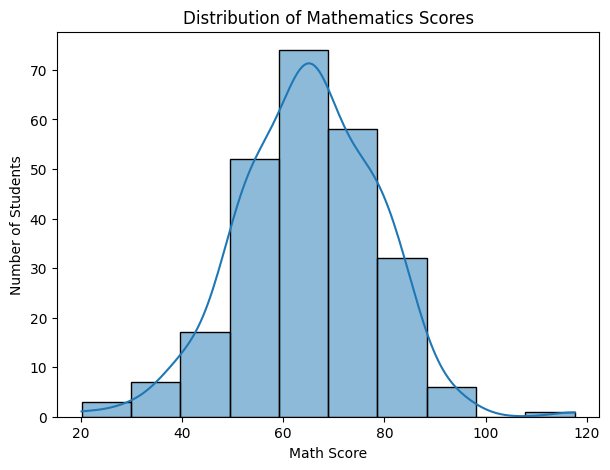

In [8]:
plt.figure(figsize=(7,5))
sns.histplot(df['math_score'], bins=10, kde=True)
plt.title("Distribution of Mathematics Scores")
plt.xlabel("Math Score")
plt.ylabel("Number of Students")
plt.show()

1. Observation: The histogram shows the distribution of mathematics scores. It helps identify the score range in which most students are concentrated.

2) Count plot -> Parental education

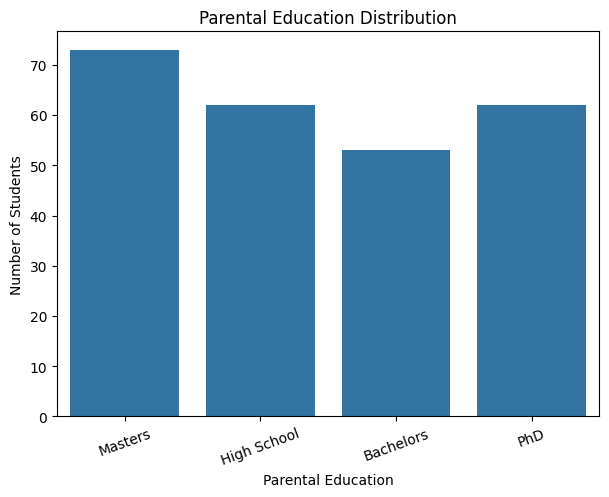

In [9]:
plt.figure(figsize=(7,5))
sns.countplot(x='parental_education', data=df)
plt.title("Parental Education Distribution")
plt.xlabel("Parental Education")
plt.ylabel("Number of Students")
plt.xticks(rotation=20)
plt.show()

2. Observation: The count plot shows the number of students in each parental education category. It helps identify the most and least common categories.

3) Box plot -> (Reading score)

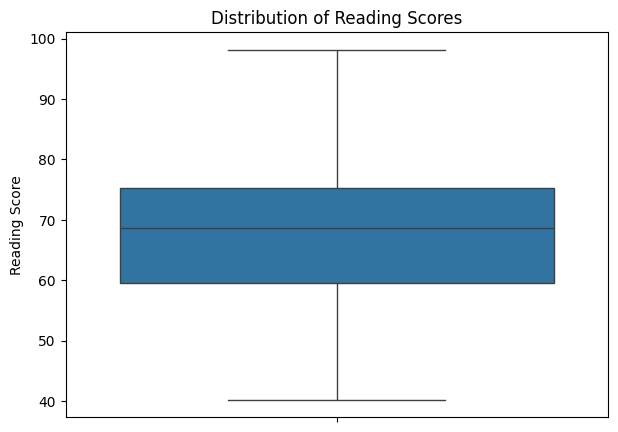

In [10]:
plt.figure(figsize=(7,5))
sns.boxplot(y=df['reading_score'])
plt.title("Distribution of Reading Scores")
plt.ylabel("Reading Score")
plt.show()

3. Observation: The box plot shows the median, minimum, maximum and spread of reading scores. It also helps identify any extreme values.

4. Count plot ->Extracurricular activities

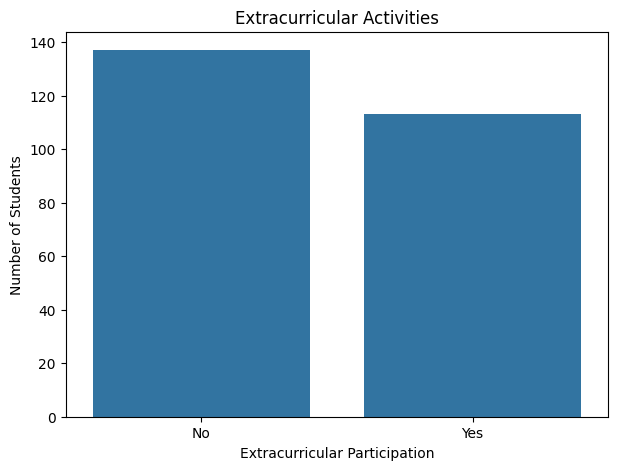

In [11]:
plt.figure(figsize=(7,5))
sns.countplot(x='extracurricular', data=df)
plt.title("Extracurricular Activities")
plt.xlabel("Extracurricular Participation")
plt.ylabel("Number of Students")
plt.show()

4. Observation: The graph shows the number of students participating and not participating in extracurricular activities. It helps compare both categories.

# ii) Bivariate analysis

1. Scatter plot – Study hours vs Mathematics score

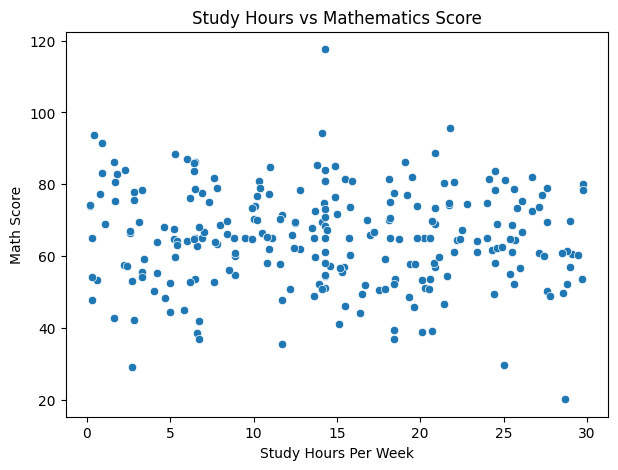

In [12]:
plt.figure(figsize=(7,5))
sns.scatterplot(x='study_hours_per_week',
                y='math_score', data=df)
plt.title("Study Hours vs Mathematics Score")
plt.xlabel("Study Hours Per Week")
plt.ylabel("Math Score")
plt.show()

Observation: The scatter plot shows the relationship between study hours and mathematics scores. It helps understand how marks vary with study hours.

2. Box plot – Final result vs Writing score

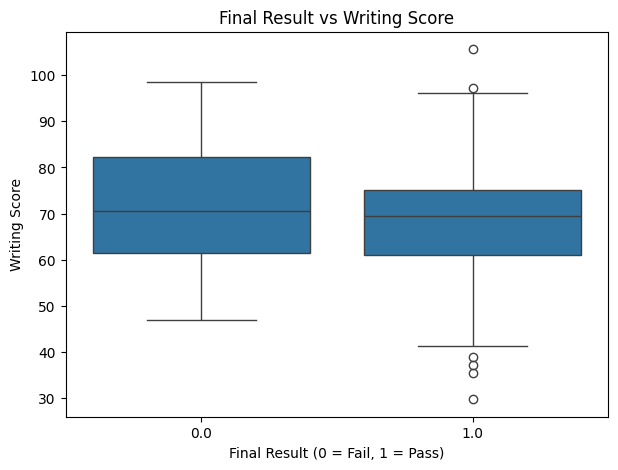

In [13]:
plt.figure(figsize=(7,5))
sns.boxplot(x='pass_final',
            y='writing_score', data=df)
plt.title("Final Result vs Writing Score")
plt.xlabel("Final Result (0 = Fail, 1 = Pass)")
plt.ylabel("Writing Score")
plt.show()

Observation: The graph compares writing scores of passed and failed students. It shows the difference in their score distributions.

3. Bar plot – Parental education vs Mathematics score

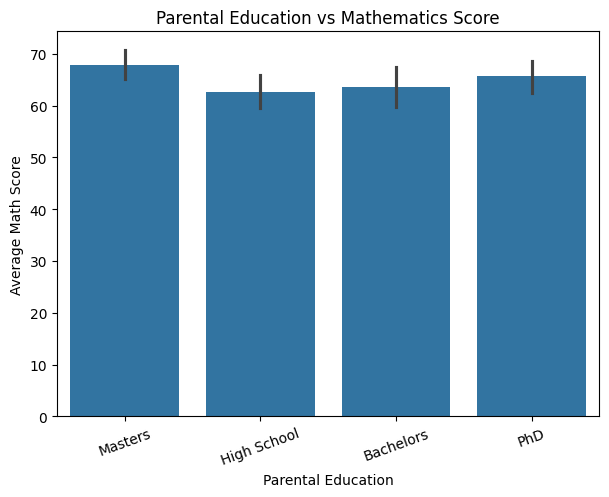

In [14]:
plt.figure(figsize=(7,5))
sns.barplot(x='parental_education',
            y='math_score', data=df)
plt.title("Parental Education vs Mathematics Score")
plt.xlabel("Parental Education")
plt.ylabel("Average Math Score")
plt.xticks(rotation=20)
plt.show()

Observation: The bar plot compares the average mathematics scores of students from different parental education categories. It helps understand the variation in average scores.

4. Count plot – Extracurricular vs Final result

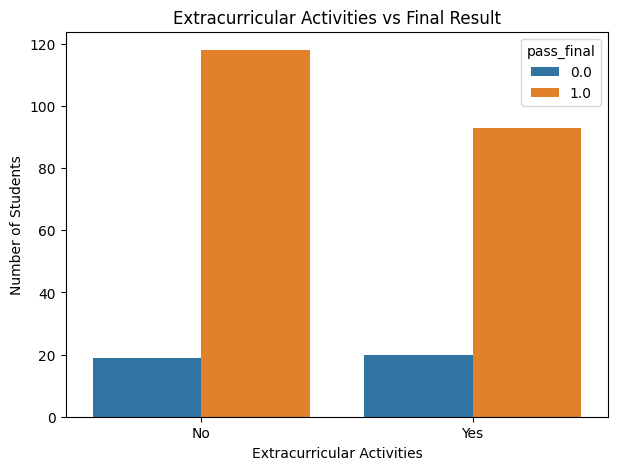

In [15]:
plt.figure(figsize=(7,5))
sns.countplot(x='extracurricular',
              hue='pass_final', data=df)
plt.title("Extracurricular Activities vs Final Result")
plt.xlabel("Extracurricular Activities")
plt.ylabel("Number of Students")
plt.show()

Observation: The graph compares the final results of students who participate and do not participate in extracurricular activities. It shows the number of passed and failed students in each group.

# iii) Multivariate Analysis

1. Heatmap – Correlation between variables

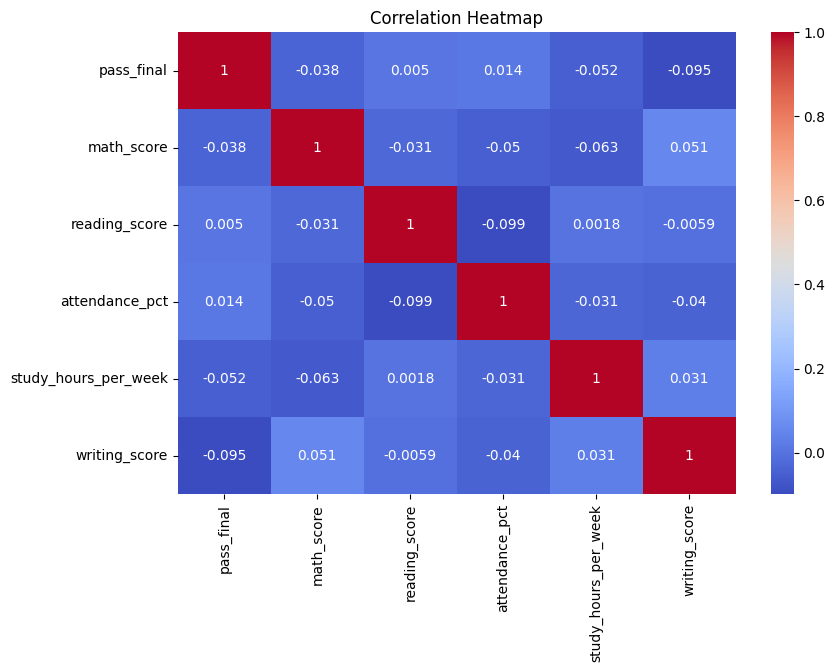

In [16]:
plt.figure(figsize=(9,6))
corr = df.select_dtypes(include='number').corr()
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.title("Correlation Heatmap")
plt.show()

Observation: The heatmap shows the correlation between numerical variables such as mathematics, reading, writing, attendance and study hours. It helps identify positive and negative relationships.

2. Pair plot – Student performance

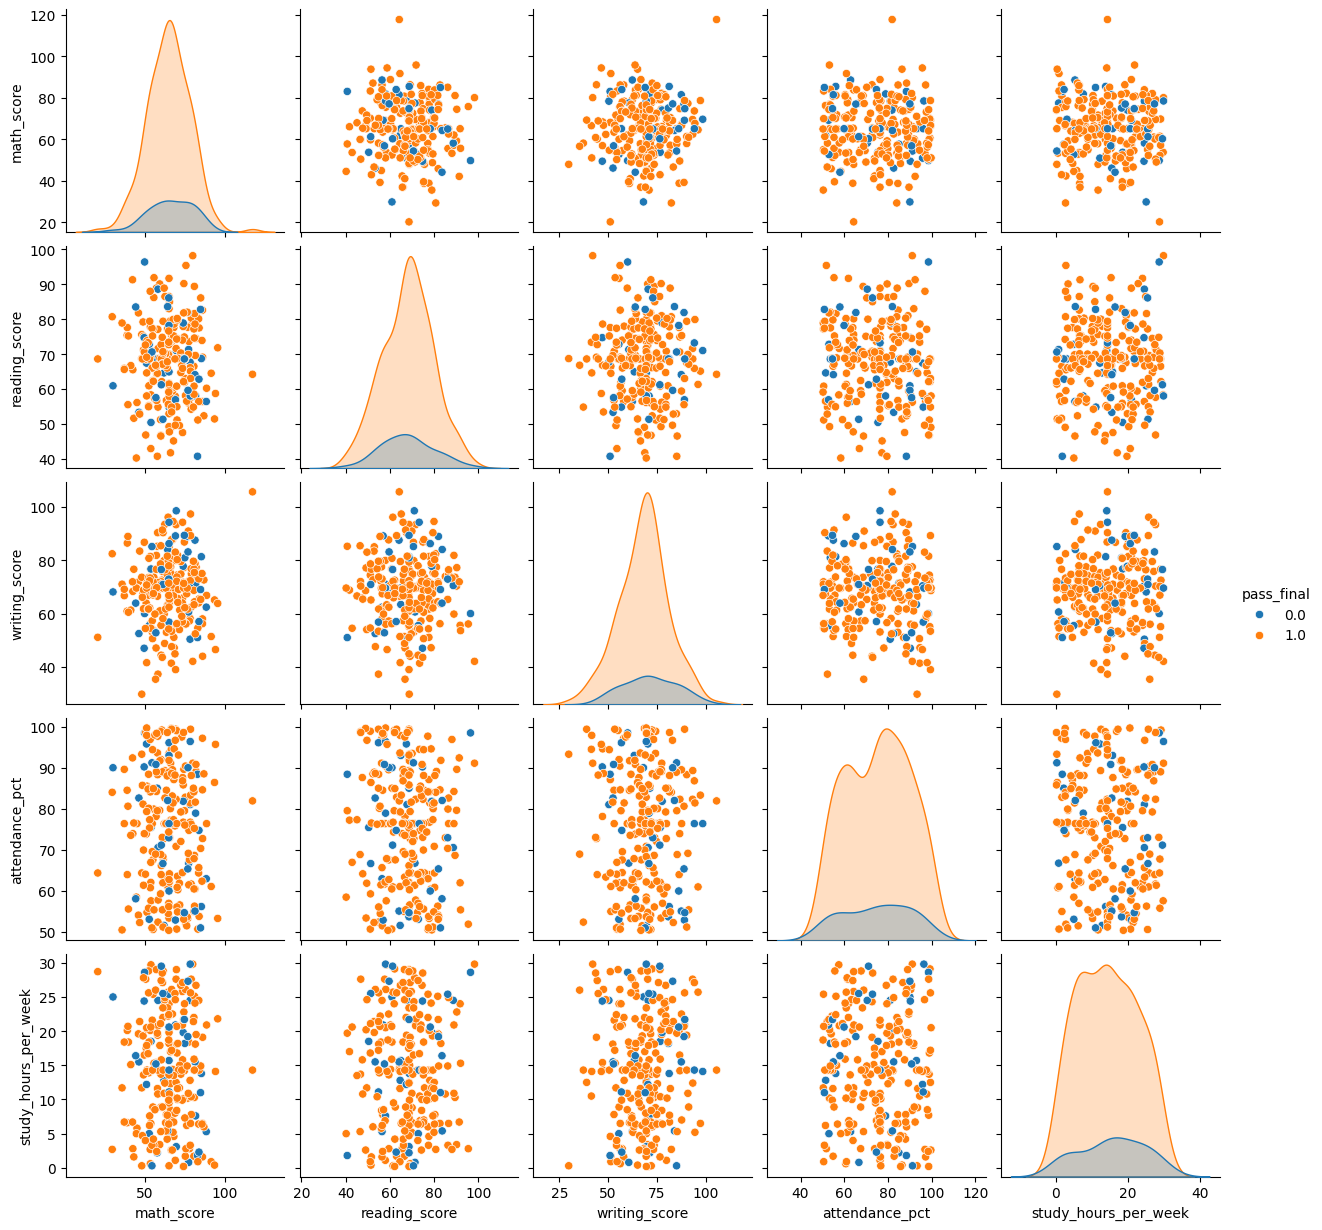

In [21]:
sns.pairplot(
    df,
    vars=['math_score', 'reading_score',
          'writing_score', 'attendance_pct',
          'study_hours_per_week'],hue='pass_final')
plt.show()

2. Observation: The pair plot compares multiple numerical variables. It displays relationships between different scores, attendance and study hours, while distinguishing passed and failed students.

3. Scatter plot – Multiple student performance factors

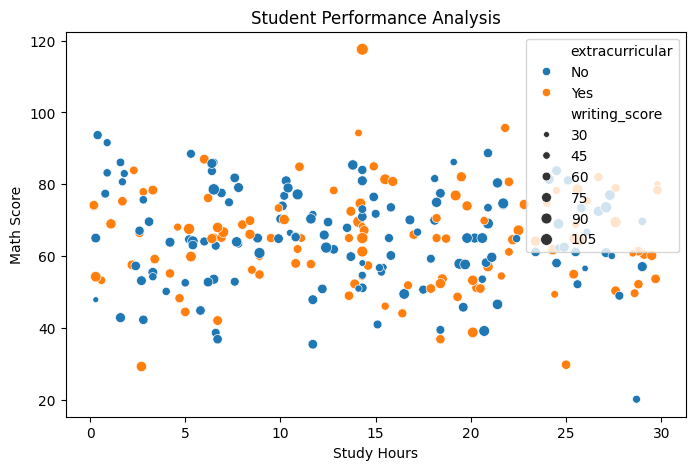

In [22]:
plt.figure(figsize=(8,5))
sns.scatterplot(
    x='study_hours_per_week',
    y='math_score',
    hue='extracurricular',
    size='writing_score',
    data=df
)
plt.title("Student Performance Analysis")
plt.xlabel("Study Hours")
plt.ylabel("Math Score")
plt.show()

3. Observation: The graph analyses study hours, mathematics scores, writing scores and extracurricular activities together. Different colours and dot sizes help compare student performance.

4. Box plot – Parental education and final result

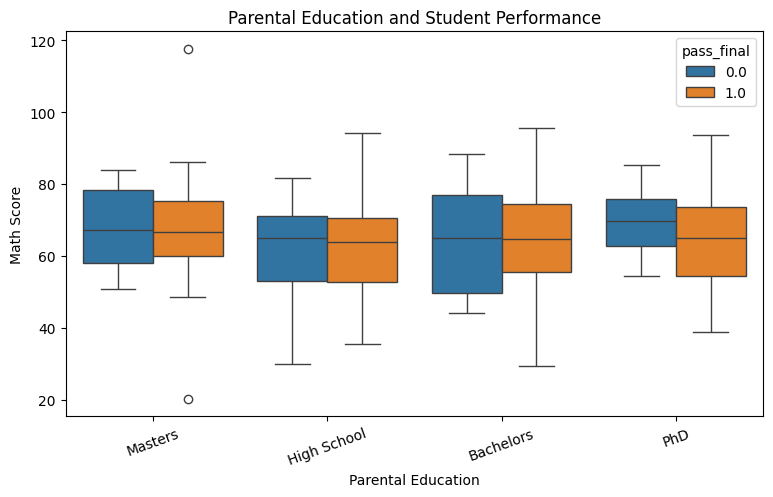

In [23]:
plt.figure(figsize=(9,5))
sns.boxplot(
    x='parental_education',
    y='math_score',
    hue='pass_final',
    data=df
)
plt.title("Parental Education and Student Performance")
plt.xlabel("Parental Education")
plt.ylabel("Math Score")
plt.xticks(rotation=20)
plt.show()

4. Observation: The box plot compares mathematics scores across parental education categories and final results. It helps understand the distribution of scores among passed and failed students.

# FINAL ANALYSIS ON THE Student Performance Data Analysis Using Python

## Objective :
To clean and analyse student performance data using Python and visualization techniques.

## Dataset :
Contains 260 records and 12 columns related to student marks, attendance, study hours and other factors.

## Libraries Used :
Pandas, NumPy, Matplotlib and Seaborn.

## Data Preprocessing :
- Missing values – Median and mode.
- Outliers – IQR method and capping.
- Duplicate rows and columns – Identified and removed.
- Categorical inconsistencies – Standardized values.

## Data Analysis :
- **Univariate:** Analysed individual variables using 4 graphs.
- **Bivariate:** Studied relationships between two variables using 4 graphs.
- **Multivariate:** Analysed multiple variables using 4 graphs.

## Output
Generated a cleaned CSV file containing 250 rows and 9 columns, along with 12 visualizations.

## Conclusion
Successfully cleaned and analysed student performance data to identify distributions, patterns and relationships among different variables.

# Generate and Download the CSV file

In [25]:
# Save the cleaned dataset as a new CSV file
df.to_csv("cleaned_student_performance.csv", index=False)
print("Cleaned CSV file created successfully!")

Cleaned CSV file created successfully!


In [27]:
from google.colab import files
files.download("cleaned_student_performance.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>